# MCDI505 · Semana 2 — Modelos clásicos (ARIMA / SARIMA)
**Estudiante:** Roberto Moncada · **Archivo:** `mcdi505_s2rmoncada.ipynb`

Este es el único notebook de la semana. El **miércoles** entregue la Hoja de decisiones completa (Formativa 2); el **domingo** entregue este mismo archivo terminado, con la hoja corregida según la retroalimentación (Sumativa 2).

> **Estado de este borrador.** Los números y los textos de «Interpretación» se generan al ejecutar el notebook (*Reiniciar kernel y ejecutar todo*). Los textos están escritos como **borrador en lenguaje sencillo** para que yo los lea, los entienda y los **reescriba con mis propias palabras** antes de entregar. Las marcas `[COMPLETAR]` son partes que debo llenar yo.

## Hoja de decisiones

| Criterio | Decisión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Estacionariedad y transformaciones | Transformar con **logaritmo** y elegir d y D con una regla fija: la menor diferenciación cuyos tests ADF y KPSS digan «estacionaria» y cuyo ACF(12) sea menor que 0,5. Valores finales de d y D: **[COMPLETAR con la celda «Apoyo para la Hoja»]** | Tabla 1 y Figura 2 (p-valores de ADF y KPSS antes y después de diferenciar); λ de Box-Cox impreso bajo la Tabla 1. **[COMPLETAR cifras]** | Dejar la serie sin transformar (la variabilidad crece con el nivel) y diferenciar más de lo necesario (sobrediferenciación) | Los pronósticos hay que volver a pasarlos a GWh con la exponencial; se pierden d + 12·D observaciones al inicio |
| 2. Identificación y estimación | Cuatro candidatos: el sugerido por la ACF/PACF, el modelo «airline» SARIMA(0,d,1)(0,D,1)₁₂, un ARMA(1,1) con la misma diferenciación y un ARIMA sin parte estacional como referencia. Todos con el indicador `covid` como regresor | Figura 3 (ACF y PACF de la serie estacionaria) y Tabla 2 (parámetros y significancia). **[COMPLETAR cifras]** | Modelos más grandes (más parámetros AR/MA), que ajustan un poco mejor pero se sobreajustan con solo 96 datos | El ARIMA sin estacionalidad sirve para medir cuánto aporta la parte estacional |
| 3. Selección y comparación | Elegir, entre los modelos con la misma diferenciación que superan al naive estacional en RMSE (validación 2023), el de mejor puntaje promedio en AIC, BIC, RMSE y MAE; si hay empate, el de menor BIC | Tabla 3 y Figura 4 (RMSE y MAE frente al naive estacional). **[COMPLETAR cifras]** | Elegir solo por AIC o solo por RMSE; el naive estacional queda como referencia mínima | El modelo elegido se usará para el diagnóstico de residuos y, en la siguiente etapa, para pronosticar |
| 4. Diagnóstico de residuos | Revisar autocorrelación (Ljung-Box en rezagos 12 y 24), normalidad (Jarque-Bera y Shapiro-Wilk) y homocedasticidad (ARCH-LM) | Tabla 4 y Figura 5 (residuos, histograma, Q-Q y ACF). **[COMPLETAR cifras]** | Dar el modelo por válido solo porque tiene buen RMSE | Si algún supuesto falla, los intervalos de pronóstico se deben leer como aproximados |

*Ejemplo de fila (ilustrativo, no corresponde a la serie del caso):* 1 · Logaritmo, d = 1, D = 1 · ADF p = 0,41 y KPSS p < 0,01 antes; ADF p < 0,01 y KPSS p > 0,10 después (Fig. 2) · Box-Cox con λ ≈ 0,05, equivalente al logaritmo y menos interpretable · Los pronósticos deberán retransformarse a GWh.

## 0. Configuración y datos

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")        # se ocultan avisos de convergencia para leer mejor el informe
SEMILLA = 505
np.random.seed(SEMILLA)

df = pd.read_csv("consumo_electrico_litoral_depurado.csv", parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]

# Partición oficial: 2024 no se utiliza esta semana
y_train = y["2015-01":"2022-12"]
y_val   = y["2023-01":"2023-12"]
print(f"Entrenamiento: {y_train.index.min():%Y-%m} a {y_train.index.max():%Y-%m} ({len(y_train)} obs.)")
print(f"Validación:    {y_val.index.min():%Y-%m} a {y_val.index.max():%Y-%m} ({len(y_val)} obs.)")

# ---- Preparación adicional (no cambia la partición) ----
S = 12                                                        # periodo estacional (meses)
covid = df["covid"].astype(float)                             # indicador oficial: mar-2020 a dic-2021
tiempo = pd.Series(np.arange(len(df)) / 12.0, index=df.index, name="tiempo")   # tiempo en años (para el "drift")
ROJO, AZUL, VERDE, GRIS, NEGRO = "#b30338", "#0057b8", "#2e7d32", "#9e9e9e", "#222222"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

def c(x, n=2):
    """Número con coma decimal."""
    return f"{x:.{n}f}".replace(".", ",")

def pv(p):
    """Valor-p con formato legible."""
    return "< 0,001" if p < 0.001 else c(p, 3)

def pp(p):
    """'p < 0,001' o 'p = 0,123' (para escribir dentro de una frase)."""
    return "p < 0,001" if p < 0.001 else "p = " + c(p, 3)

PALABRAS = {}
def interpretacion(seccion, texto):
    """Muestra el texto de interpretación y cuenta sus palabras (límite de la evaluación: 250)."""
    n = len(texto.split())
    PALABRAS[seccion] = n
    display(Markdown(texto + f"\n\n*({n} palabras; límite 250)*"))

print("Meses con indicador covid:", int(covid.sum()), "· imputados:", int(df["imputado"].sum()),
      "· atípico corregido:", int(df["atipico_corregido"].sum()))

Entrenamiento: 2015-01 a 2022-12 (96 obs.)
Validación:    2023-01 a 2023-12 (12 obs.)
Meses con indicador covid: 22 · imputados: 3 · atípico corregido: 1


**Contexto del conjunto de datos.** La serie es el consumo eléctrico mensual (GWh) del segmento comercial de la Distribuidora Eléctrica del Litoral, con 120 meses (2015-2024) y datos sintéticos. Uso la versión depurada oficial: ya trae imputados los tres meses faltantes (`imputado`), corregido el atípico de noviembre de 2017 (`atipico_corregido`) y un indicador del periodo COVID-19 (`covid`, marzo de 2020 a diciembre de 2021). Esta semana entreno con 2015-2022 (96 meses) y valido con 2023 (12 meses); el año 2024 no se usa. Trabajo solo con `consumo_gwh` y el periodo estacional es 12.

## 1. Análisis de estacionariedad y transformaciones

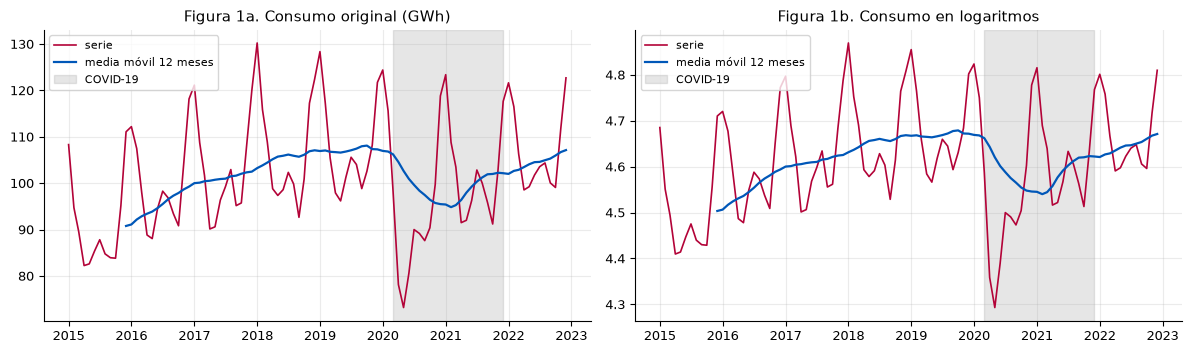

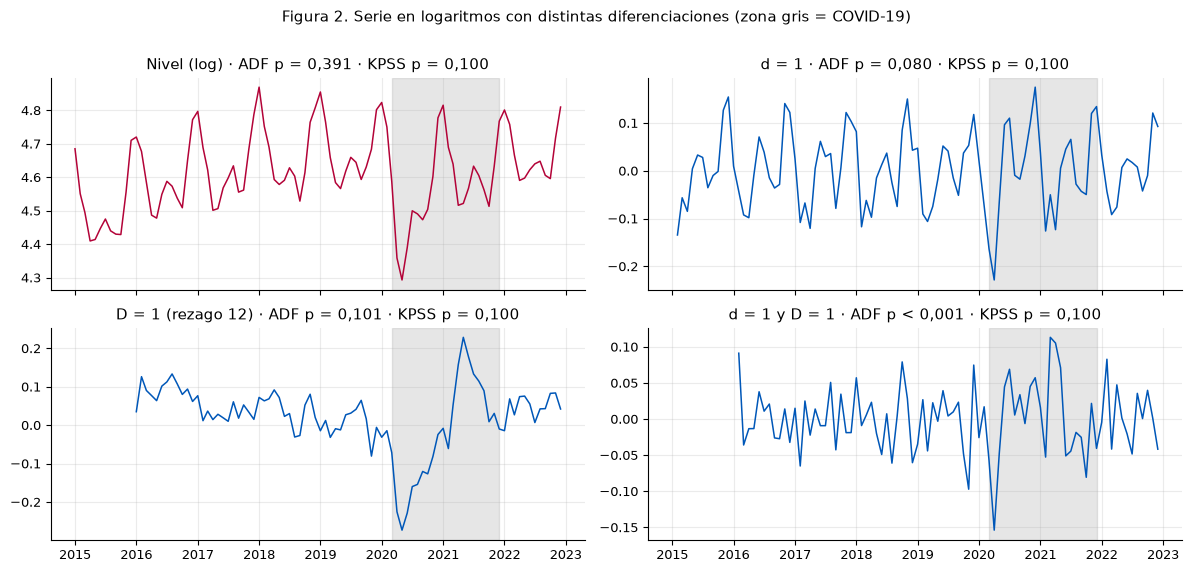

Tabla 1. Pruebas de raíz unitaria (entrenamiento 2015-2022). ADF: H0 = raíz unitaria; KPSS: H0 = estacionaria


,ADF p,KPSS p,desv. est.,ACF(12),veredicto
"Nivel (original, GWh)",0.476,0.1,12.095,0.665,Discrepante / no concluyente
Nivel (log),0.391,0.1,0.119,0.621,Discrepante / no concluyente
d = 1,0.080,0.1,0.080,0.757,Discrepante / no concluyente
D = 1 (rezago 12),0.101,0.1,0.085,-0.228,Discrepante / no concluyente
d = 1 y D = 1,0.000,0.1,0.047,-0.298,Estacionaria


λ de Box-Cox = 0.00 · decisión de la regla: d = 1, D = 1


In [2]:
# ============================================================
# 1. Transformación (Box-Cox/log), tests ADF y KPSS y decisión de d y D  (solo datos de entrenamiento)
# ============================================================
ly_train = np.log(y_train)                                   # serie en logaritmos
lam = float(stats.boxcox_normmax(y_train.values, method="mle"))

def evaluar(x, reg):
    """ADF + KPSS + dos señales auxiliares (desviación estándar y ACF en el rezago 12)."""
    x = x.dropna()
    a_est, a_p = adfuller(x, regression=reg, autolag="AIC")[:2]
    k_est, k_p = kpss(x, regression=reg, nlags="auto")[:2]
    if a_p < 0.05 and k_p >= 0.05:
        ver = "Estacionaria"
    elif a_p >= 0.05 and k_p < 0.05:
        ver = "No estacionaria"
    else:
        ver = "Discrepante / no concluyente"
    return {"ADF p": a_p, "KPSS p": k_p, "desv. est.": float(x.std()),
            "ACF(12)": float(acf(x, nlags=S)[S]), "veredicto": ver}

opciones = {(0, 0): ly_train, (1, 0): ly_train.diff(), (0, 1): ly_train.diff(S), (1, 1): ly_train.diff().diff(S)}
nombres = {(0, 0): "Nivel (log)", (1, 0): "d = 1", (0, 1): "D = 1 (rezago 12)", (1, 1): "d = 1 y D = 1"}
pruebas = {k: evaluar(v, "ct" if k == (0, 0) else "c") for k, v in opciones.items()}
ref_orig = evaluar(y_train, "ct")                            # referencia: serie original sin log

# Regla fijada de antemano: menor diferenciación con veredicto "Estacionaria" y ACF(12) < 0,5
d_sel, D_sel, cumple = 1, 1, False
for k in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    if pruebas[k]["veredicto"] == "Estacionaria" and pruebas[k]["ACF(12)"] < 0.5:
        (d_sel, D_sel), cumple = k, True
        break
w = opciones[(d_sel, D_sel)].dropna()                        # serie estacionaria que se usará en la sección 2

# ---- Figura 1: serie original y en logaritmos ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, serie, tit in zip(axes, [y_train, ly_train], ["Figura 1a. Consumo original (GWh)", "Figura 1b. Consumo en logaritmos"]):
    ax.plot(serie, color=ROJO, lw=1.2, label="serie")
    ax.plot(serie.rolling(12).mean(), color=AZUL, lw=1.6, label="media móvil 12 meses")
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=GRIS, alpha=0.25, label="COVID-19")
    ax.set_title(tit); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

# ---- Figura 2: series con las distintas diferenciaciones ----
fig, axes = plt.subplots(2, 2, figsize=(12, 5.6), sharex=True)
for ax, (k, serie) in zip(axes.ravel(), opciones.items()):
    ax.plot(serie.dropna(), color=ROJO if k == (0, 0) else AZUL, lw=1.1)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=GRIS, alpha=0.25)
    ax.set_title(f"{nombres[k]} · ADF {pp(pruebas[k]['ADF p'])} · KPSS {pp(pruebas[k]['KPSS p'])}")
fig.suptitle("Figura 2. Serie en logaritmos con distintas diferenciaciones (zona gris = COVID-19)", y=1.01, fontsize=11)
plt.tight_layout(); plt.show()

# ---- Tabla 1 ----
tab1 = pd.DataFrame({"Nivel (original, GWh)": ref_orig, **{nombres[k]: v for k, v in pruebas.items()}}).T
tab1[["ADF p", "KPSS p", "desv. est.", "ACF(12)"]] = tab1[["ADF p", "KPSS p", "desv. est.", "ACF(12)"]].astype(float).round(3)
print("Tabla 1. Pruebas de raíz unitaria (entrenamiento 2015-2022). ADF: H0 = raíz unitaria; KPSS: H0 = estacionaria")
display(tab1)
print(f"λ de Box-Cox = {lam:.2f} · decisión de la regla: d = {d_sel}, D = {D_sel}")

In [3]:
# Interpretación de la sección 1 (borrador generado a partir de los resultados)
f0, fs = pruebas[(0, 0)], pruebas[(d_sel, D_sel)]
frase_lam = ("más cerca de 0 (logaritmo) que de 1 (sin transformar)" if lam < 0.5 else "más cerca de 1 que de 0, así que el logaritmo no es obligatorio")
regla = ("cumple la regla" if cumple else "no cumplió la regla, por eso uso la opción por defecto (1, 1)")
extra = ""
if (d_sel, D_sel) != (1, 1):
    extra = " No agregué una diferencia regular extra porque aumentaría la variabilidad sin necesidad."
elif cumple:
    extra = " Las diferenciaciones más simples no bastaron para cumplir las dos condiciones."
texto = (
    "**Borrador (reescribir con mis palabras).** "
    f"Primero revisé la transformación: el λ de Box-Cox es {c(lam)}, {frase_lam}, y como la variabilidad crece con el nivel (Figura 1) trabajé con logaritmos. "
    f"Luego apliqué ADF y KPSS (Tabla 1). En la serie en nivel, ADF da {pp(f0['ADF p'])} y KPSS {pp(f0['KPSS p'])}, con veredicto «{f0['veredicto'].lower()}», y el rezago 12 de la ACF vale {c(f0['ACF(12)'])}: todavía hay una estacionalidad fuerte. "
    f"Como regla elegí la menor diferenciación cuyos dos tests digan «estacionaria» y cuyo ACF(12) sea menor que 0,5. La combinación elegida es d = {d_sel} y D = {D_sel}, que {regla}: ADF {pp(fs['ADF p'])}, KPSS {pp(fs['KPSS p'])}, ACF(12) = {c(fs['ACF(12)'])} y veredicto «{fs['veredicto'].lower()}».{extra} "
    "La Figura 2 muestra que, después de diferenciar, la serie oscila alrededor de un valor constante, salvo en el periodo COVID-19, donde la variabilidad aumenta; por eso el indicador `covid` irá como regresor en los modelos. "
    f"Con esto la serie queda lista para identificar modelos (se pierden {d_sel + D_sel * S} observaciones al diferenciar)."
)
interpretacion("1", texto)

**Borrador (reescribir con mis palabras).** Primero revisé la transformación: el λ de Box-Cox es 0,00, más cerca de 0 (logaritmo) que de 1 (sin transformar), y como la variabilidad crece con el nivel (Figura 1) trabajé con logaritmos. Luego apliqué ADF y KPSS (Tabla 1). En la serie en nivel, ADF da p = 0,391 y KPSS p = 0,100, con veredicto «discrepante / no concluyente», y el rezago 12 de la ACF vale 0,62: todavía hay una estacionalidad fuerte. Como regla elegí la menor diferenciación cuyos dos tests digan «estacionaria» y cuyo ACF(12) sea menor que 0,5. La combinación elegida es d = 1 y D = 1, que cumple la regla: ADF p < 0,001, KPSS p = 0,100, ACF(12) = -0,30 y veredicto «estacionaria». Las diferenciaciones más simples no bastaron para cumplir las dos condiciones. La Figura 2 muestra que, después de diferenciar, la serie oscila alrededor de un valor constante, salvo en el periodo COVID-19, donde la variabilidad aumenta; por eso el indicador `covid` irá como regresor en los modelos. Con esto la serie queda lista para identificar modelos (se pierden 13 observaciones al diferenciar).

*(189 palabras; límite 250)*

## 2. Identificación y estimación de modelos

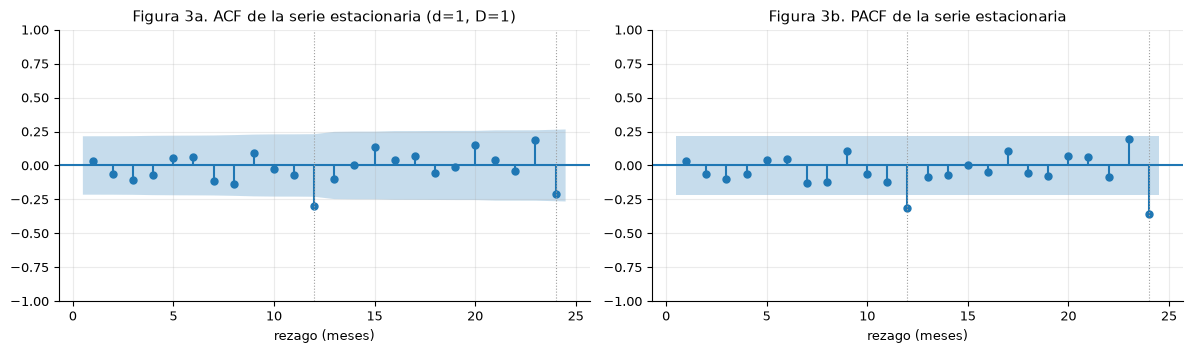

Banda 95 % = ±0.215 · rezagos ACF significativos: [12] · rezagos PACF significativos: [12, 24]


Tabla 2. Modelos candidatos estimados con el entrenamiento 2015-2022 (serie en logaritmos)


,familia,orden,parámetros,AR/MA no signif.,efecto covid (%),p covid,convergió
modelo,,,,,,,
A. SARIMA sugerido por ACF/PACF,SARIMA,"(0,1,0)(0,1,1)[12]",3,1,-4.186,0.030,True
B. SARIMA tipo «airline»,SARIMA,"(0,1,1)(0,1,1)[12]",4,1,-5.987,0.000,True
"C. ARMA(1,1) con la misma diferenciación",ARMA,"(1,1,1)(0,1,0)[12]",4,0,-6.021,0.002,True
D. ARIMA sin parte estacional (referencia),ARIMA,"(1,1,1)",5,1,-0.781,0.787,True


In [4]:
# ============================================================
# 2. ACF/PACF de la serie estacionaria, candidatos y estimación (entrenamiento 2015-2022)
# ============================================================
NL = 24
r_w, p_w = acf(w, nlags=NL), pacf(w, nlags=NL, method="ywm")
banda = 1.96 / np.sqrt(len(w))
sig_acf = [k for k in range(1, NL + 1) if abs(r_w[k]) > banda]
sig_pacf = [k for k in range(1, NL + 1) if abs(p_w[k]) > banda]

# ---- Figura 3: ACF y PACF ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(w, lags=NL, ax=axes[0], zero=False, title=f"Figura 3a. ACF de la serie estacionaria (d={d_sel}, D={D_sel})")
plot_pacf(w, lags=NL, ax=axes[1], zero=False, method="ywm", title="Figura 3b. PACF de la serie estacionaria")
for ax in axes:
    ax.set_xlabel("rezago (meses)")
    for k in (12, 24):
        ax.axvline(k, color=GRIS, ls=":", lw=0.8)
plt.tight_layout(); plt.show()
print(f"Banda 95 % = ±{banda:.3f} · rezagos ACF significativos: {sig_acf} · rezagos PACF significativos: {sig_pacf}")

# ---- Órdenes sugeridos por la evidencia (regla explícita) ----
def mayor_corto(sig, tope=3):
    cortos = [k for k in sig if k <= tope]
    return max(cortos) if cortos else 0

p_sug = min(mayor_corto(sig_pacf), 2)                 # AR no estacional (máx. 2 para no sobreajustar)
q_sug = min(mayor_corto(sig_acf), 2)                  # MA no estacional
Q_sug = int(S in sig_acf)                             # MA estacional si la ACF es significativa en 12
P_sug = int((S in sig_pacf) and (S not in sig_acf))   # AR estacional si solo la PACF lo es

# ---- Candidatos: (nombre, familia, (p, d, q, P, D, Q)) ----
d, D = d_sel, D_sel
candidatos = [
    ("A. SARIMA sugerido por ACF/PACF", "SARIMA", (p_sug, d, q_sug, P_sug, D, Q_sug)),
    ("B. SARIMA tipo «airline»",        "SARIMA", (0, d, 1, 0, D, 1)),
    ("C. ARMA(1,1) con la misma diferenciación", "ARMA", (1, d, 1, 0, D, 0)),
    ("D. ARIMA sin parte estacional (referencia)", "ARIMA", (1, 1, 1, 0, 0, 0)),
]
vistos, unicos = set(), []
for nom, fam, spec in candidatos:
    if spec in vistos:                                # si el sugerido repite a otro, se cambia por una variante vecina
        spec = (1, d, 0, 0, D, 1)
        nom = nom + " (variante: AR(1) + MA estacional)"
    vistos.add(spec)
    unicos.append((nom, fam, spec))
candidatos = unicos

# ---- Estimación ----
def exog_modelo(idx, d_, D_):
    """Regresores: indicador covid y, si la diferenciación total es 1, una tendencia lineal (drift)."""
    X = pd.DataFrame({"covid": covid.loc[idx]})
    if d_ + D_ == 1:
        X["tiempo"] = tiempo.loc[idx]
    return X

def ajustar(serie, spec):
    p, d_, q, P, D_, Q = spec
    mod = SARIMAX(serie, exog=exog_modelo(serie.index, d_, D_), order=(p, d_, q),
                  seasonal_order=(P, D_, Q, S if (P or D_ or Q) else 0), trend="c" if d_ + D_ == 0 else "n")
    return mod.fit(disp=False, maxiter=200)

resultados, filas = {}, []
for nom, fam, spec in candidatos:
    try:
        res = ajustar(ly_train, spec)
    except Exception as e:
        print(f"[aviso] {nom} no se pudo estimar: {type(e).__name__}")
        continue
    pvs = res.pvalues[[n for n in res.pvalues.index if n.startswith(("ar.", "ma."))]]
    resultados[nom] = {"spec": spec, "res": res, "k_arma": len(pvs)}
    p, d_, q, P, D_, Q = spec
    filas.append({"modelo": nom, "familia": fam, "orden": f"({p},{d_},{q})({P},{D_},{Q})[{S}]" if (P or D_ or Q) else f"({p},{d_},{q})",
                  "parámetros": len(res.params), "AR/MA no signif.": int((pvs >= 0.05).sum()),
                  "efecto covid (%)": 100 * (np.exp(res.params["covid"]) - 1), "p covid": res.pvalues["covid"],
                  "convergió": bool(res.mle_retvals.get("converged", True)) if getattr(res, "mle_retvals", None) else True})
tab2 = pd.DataFrame(filas).set_index("modelo")
tab2[["efecto covid (%)", "p covid"]] = tab2[["efecto covid (%)", "p covid"]].round(3)
print("Tabla 2. Modelos candidatos estimados con el entrenamiento 2015-2022 (serie en logaritmos)")
display(tab2)

In [5]:
# Interpretación de la sección 2 (borrador)
nom_A = candidatos[0][0]
cov_A = tab2.loc[nom_A, "efecto covid (%)"] if nom_A in tab2.index else float("nan")
texto = (
    "**Borrador (reescribir con mis palabras).** "
    f"Después de diferenciar (d = {d_sel}, D = {D_sel}), miré la ACF y la PACF (Figura 3; banda ±{c(banda, 2)}). "
    f"La ACF tiene rezagos significativos en {sig_acf if sig_acf else 'ninguno'} y la PACF en {sig_pacf if sig_pacf else 'ninguno'}. "
    f"Para la parte de corto plazo, la regla que usé (último rezago significativo entre 1 y 3, con máximo 2) da p = {p_sug} y q = {q_sug}. "
    f"En el rezago 12 la ACF vale {c(r_w[S])} ({'significativa' if S in sig_acf else 'no significativa'}) y la PACF {c(p_w[S])} ({'significativa' if S in sig_pacf else 'no significativa'}), lo que sugiere P = {P_sug} y Q = {Q_sug}. "
    f"Con eso propuse cuatro candidatos (Tabla 2): el sugerido, el «airline», un ARMA(1,1) y un ARIMA sin parte estacional que sirve de referencia. "
    "Todos llevan el indicador `covid` como regresor. "
    f"En el modelo A, el efecto estimado del COVID-19 es de {c(cov_A, 1)} % sobre el nivel esperado. "
    f"En la columna «AR/MA no signif.» se ve cuántos parámetros no aportan; si hay muchos, el modelo es más complejo de lo necesario. "
    "Los cuatro modelos se estimaron solo con el entrenamiento, así que 2023 sigue siendo una validación honesta."
)
interpretacion("2", texto)

**Borrador (reescribir con mis palabras).** Después de diferenciar (d = 1, D = 1), miré la ACF y la PACF (Figura 3; banda ±0,22). La ACF tiene rezagos significativos en [12] y la PACF en [12, 24]. Para la parte de corto plazo, la regla que usé (último rezago significativo entre 1 y 3, con máximo 2) da p = 0 y q = 0. En el rezago 12 la ACF vale -0,30 (significativa) y la PACF -0,32 (significativa), lo que sugiere P = 0 y Q = 1. Con eso propuse cuatro candidatos (Tabla 2): el sugerido, el «airline», un ARMA(1,1) y un ARIMA sin parte estacional que sirve de referencia. Todos llevan el indicador `covid` como regresor. En el modelo A, el efecto estimado del COVID-19 es de -4,2 % sobre el nivel esperado. En la columna «AR/MA no signif.» se ve cuántos parámetros no aportan; si hay muchos, el modelo es más complejo de lo necesario. Los cuatro modelos se estimaron solo con el entrenamiento, así que 2023 sigue siendo una validación honesta.

*(176 palabras; límite 250)*

## 3. Selección y comparación de modelos

Naive estacional — RMSE: 7.26 | MAE: 6.53
Tabla 3. Comparación en validación 2023 (RMSE y MAE en GWh). AIC y BIC solo son comparables con la misma diferenciación (d, D); se elige, entre los que superan al naive en RMSE, el de mejor puntaje (empate: menor BIC)


,AIC,BIC,RMSE,MAE,MAPE %,puntaje,supera naive (RMSE)
modelo,,,,,,,
A. SARIMA sugerido por ACF/PACF,-300.921,-293.664,7.763,7.335,6.513,2.0,No
B. SARIMA tipo «airline»,-300.903,-291.228,7.134,6.681,5.934,2.0,Sí
"C. ARMA(1,1) con la misma diferenciación",-276.199,-266.524,6.687,5.885,5.055,2.0,Sí
D. ARIMA sin parte estacional (referencia),-235.433,-222.664,17.482,15.966,14.668,NaN,
Naive estacional (referencia),NaN,NaN,7.263,6.528,5.639,NaN,


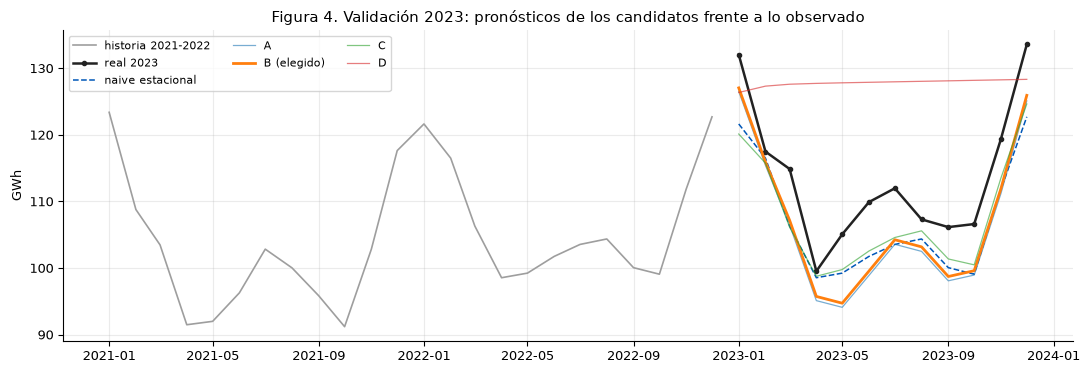

In [6]:
# Referencia obligatoria: naive estacional (repite el valor del mismo mes del año anterior)
naive_val = y["2022-01":"2022-12"].to_numpy()
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
mae  = lambda e: float(np.mean(np.abs(e)))
print(f"Naive estacional — RMSE: {rmse(y_val.to_numpy() - naive_val):.2f} | MAE: {mae(y_val.to_numpy() - naive_val):.2f}")

# ============================================================
# 3. AIC, BIC, RMSE y MAE en validación 2023 para los candidatos
# ============================================================
real = y_val.to_numpy()
filas3, pred_val = [], {}
for nom, r in resultados.items():
    p, d_, q, P, D_, Q = r["spec"]
    fc = r["res"].get_forecast(steps=12, exog=exog_modelo(y_val.index, d_, D_))
    pred = np.exp(np.asarray(fc.predicted_mean))              # se vuelve a GWh
    pred_val[nom] = pd.Series(pred, index=y_val.index)
    filas3.append({"modelo": nom, "d": d_, "D": D_, "AIC": r["res"].aic, "BIC": r["res"].bic,
                   "RMSE": rmse(real - pred), "MAE": mae(real - pred),
                   "MAPE %": float(np.mean(np.abs(real - pred) / real) * 100)})
filas3.append({"modelo": "Naive estacional (referencia)", "d": np.nan, "D": np.nan, "AIC": np.nan, "BIC": np.nan,
               "RMSE": rmse(real - naive_val), "MAE": mae(real - naive_val),
               "MAPE %": float(np.mean(np.abs(real - naive_val) / real) * 100)})
tab3 = pd.DataFrame(filas3).set_index("modelo")

# Regla de selección: mejor ranking promedio (AIC, BIC, RMSE, MAE) entre modelos con la misma diferenciación
comparable = (tab3["d"] == d_sel) & (tab3["D"] == D_sel)
tab3["puntaje"] = np.nan
tab3.loc[comparable, "puntaje"] = tab3.loc[comparable, ["AIC", "BIC", "RMSE", "MAE"]].rank().mean(axis=1)
rmse_naive = tab3.loc["Naive estacional (referencia)", "RMSE"]
tab3["supera naive (RMSE)"] = np.where(comparable, np.where(tab3["RMSE"] < rmse_naive, "Sí", "No"), "")
orden = tab3.loc[comparable].sort_values(["puntaje", "BIC"]).index.tolist()
elegibles = [m for m in orden if tab3.loc[m, "RMSE"] < rmse_naive]      # condición de la Hoja de decisiones
seleccion = elegibles[0] if elegibles else orden[0]                   # si ninguno supera al naive, se informa
empatados = [m for m in elegibles if tab3.loc[m, "puntaje"] == tab3.loc[seleccion, "puntaje"]]
sel = resultados[seleccion]
supera = tab3.loc[seleccion, "RMSE"] < rmse_naive
print("Tabla 3. Comparación en validación 2023 (RMSE y MAE en GWh). AIC y BIC solo son comparables con la misma diferenciación (d, D); "
      "se elige, entre los que superan al naive en RMSE, el de mejor puntaje (empate: menor BIC)")
display(tab3.drop(columns=["d", "D"]).round(3))

# ---- Figura 4: pronósticos de validación ----
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(y["2021-01":"2022-12"], color=GRIS, lw=1.2, label="historia 2021-2022")
ax.plot(y_val, color=NEGRO, lw=1.8, marker="o", ms=3, label="real 2023")
ax.plot(y_val.index, naive_val, color=AZUL, lw=1.1, ls="--", label="naive estacional")
for nom, s_ in pred_val.items():
    ax.plot(s_, lw=2.0 if nom == seleccion else 0.9, alpha=1 if nom == seleccion else 0.6, label=nom.split(".")[0] + (" (elegido)" if nom == seleccion else ""))
ax.set_ylabel("GWh"); ax.legend(fontsize=8, ncol=3)
ax.set_title("Figura 4. Validación 2023: pronósticos de los candidatos frente a lo observado")
plt.tight_layout(); plt.show()

In [7]:
# Interpretación de la sección 3 (borrador)
fs = tab3.loc[seleccion]; fn = tab3.loc["Naive estacional (referencia)"]
mejor_aic = tab3.loc[comparable, "AIC"].idxmin(); mejor_bic = tab3.loc[comparable, "BIC"].idxmin()
mejor_rmse = tab3.loc[comparable, "RMSE"].idxmin()
siglas = lambda n: n.split(".")[0]
nota_ref = ""
if "D. ARIMA sin parte estacional (referencia)" in tab3.index:
    fd = tab3.loc["D. ARIMA sin parte estacional (referencia)"]
    nota_ref = f" El ARIMA sin parte estacional tuvo RMSE = {c(fd['RMSE'])} GWh, por lo que {'no ' if fd['RMSE'] >= fs['RMSE'] else ''}supera al elegido; esto muestra {'cuánto aporta' if fd['RMSE'] >= fs['RMSE'] else 'que no era necesaria'} la parte estacional."
texto = (
    "**Borrador (reescribir con mis palabras).** "
    f"Comparé los candidatos con AIC y BIC (ajuste con penalización) y con RMSE y MAE en 2023 (Tabla 3). Como AIC y BIC solo se pueden comparar con la misma diferenciación, el ranking usa los modelos con d = {d_sel} y D = {D_sel}. "
    f"El menor AIC es del modelo {siglas(mejor_aic)}, el menor BIC del {siglas(mejor_bic)} y el menor RMSE del {siglas(mejor_rmse)}. "
    f"{'Los criterios coinciden en el mismo modelo.' if len({mejor_aic, mejor_bic, mejor_rmse}) == 1 else 'Los criterios no coinciden del todo, por eso los combiné en un ranking promedio.'} "
    + (f"Como regla, el elegido debe superar al naive estacional en RMSE ({c(fn['RMSE'])} GWh); {'no lo supera' if len(orden) - len(elegibles) == 1 else 'no lo superan'} {', '.join(siglas(m) for m in orden if m not in elegibles)}. " if len(elegibles) < len(orden) else f"Todos los candidatos comparables superan al naive estacional en RMSE ({c(fn['RMSE'])} GWh). ")
    + (f"Entre los que sí lo superan, {' y '.join(siglas(m) for m in empatados)} empatan en el ranking promedio ({c(fs['puntaje'], 1)}) y el desempate es el menor BIC. " if len(empatados) > 1 else "")
    + (f"Elegí el modelo {seleccion}: AIC = {c(fs['AIC'], 1)}, BIC = {c(fs['BIC'], 1)}, RMSE = {c(fs['RMSE'])} GWh y MAE = {c(fs['MAE'])} GWh. " if elegibles else f"Ningún candidato supera al naive estacional, así que conservo el de mejor puntaje, {seleccion}, como señal de alerta sobre su utilidad. ")
    + (f"Frente al naive, mejora el RMSE en {c(100 * (1 - fs['RMSE'] / fn['RMSE']), 1)} %, " if supera else "")
    + f"{'y' if supera else 'Además,'} en MAE {'también lo supera' if fs['MAE'] < fn['MAE'] else 'no lo supera'} ({c(fs['MAE'])} frente a {c(fn['MAE'])} GWh)."
    + nota_ref + " "
    "Como la validación son solo 12 meses, estas diferencias deben leerse con cautela."
)
interpretacion("3", texto)

**Borrador (reescribir con mis palabras).** Comparé los candidatos con AIC y BIC (ajuste con penalización) y con RMSE y MAE en 2023 (Tabla 3). Como AIC y BIC solo se pueden comparar con la misma diferenciación, el ranking usa los modelos con d = 1 y D = 1. El menor AIC es del modelo A, el menor BIC del A y el menor RMSE del C. Los criterios no coinciden del todo, por eso los combiné en un ranking promedio. Como regla, el elegido debe superar al naive estacional en RMSE (7,26 GWh); no lo supera A. Entre los que sí lo superan, B y C empatan en el ranking promedio (2,0) y el desempate es el menor BIC. Elegí el modelo B. SARIMA tipo «airline»: AIC = -300,9, BIC = -291,2, RMSE = 7,13 GWh y MAE = 6,68 GWh. Frente al naive, mejora el RMSE en 1,8 %, y en MAE no lo supera (6,68 frente a 6,53 GWh). El ARIMA sin parte estacional tuvo RMSE = 17,48 GWh, por lo que no supera al elegido; esto muestra cuánto aporta la parte estacional. Como la validación son solo 12 meses, estas diferencias deben leerse con cautela.

*(199 palabras; límite 250)*

## 4. Diagnóstico de residuos y validación de supuestos

Tabla 4. Pruebas sobre los residuos de B. SARIMA tipo «airline» (n = 83; Ljung-Box con 2 parámetros AR/MA descontados)


,prueba,estadístico,valor-p,conclusión (5 %)
supuesto,,,,
Sin autocorrelación,"Ljung-Box, rezago 12",11.034,0.355,Cumple
Sin autocorrelación,"Ljung-Box, rezago 24",33.085,0.061,Cumple
Normalidad,Jarque-Bera,13.402,0.001,No cumple
Normalidad,Shapiro-Wilk,0.964,0.019,No cumple
Homocedasticidad,ARCH-LM (12 rezagos),9.734,0.639,Cumple
Homocedasticidad,F de varianzas (2.ª / 1.ª mitad),1.446,0.246,Cumple


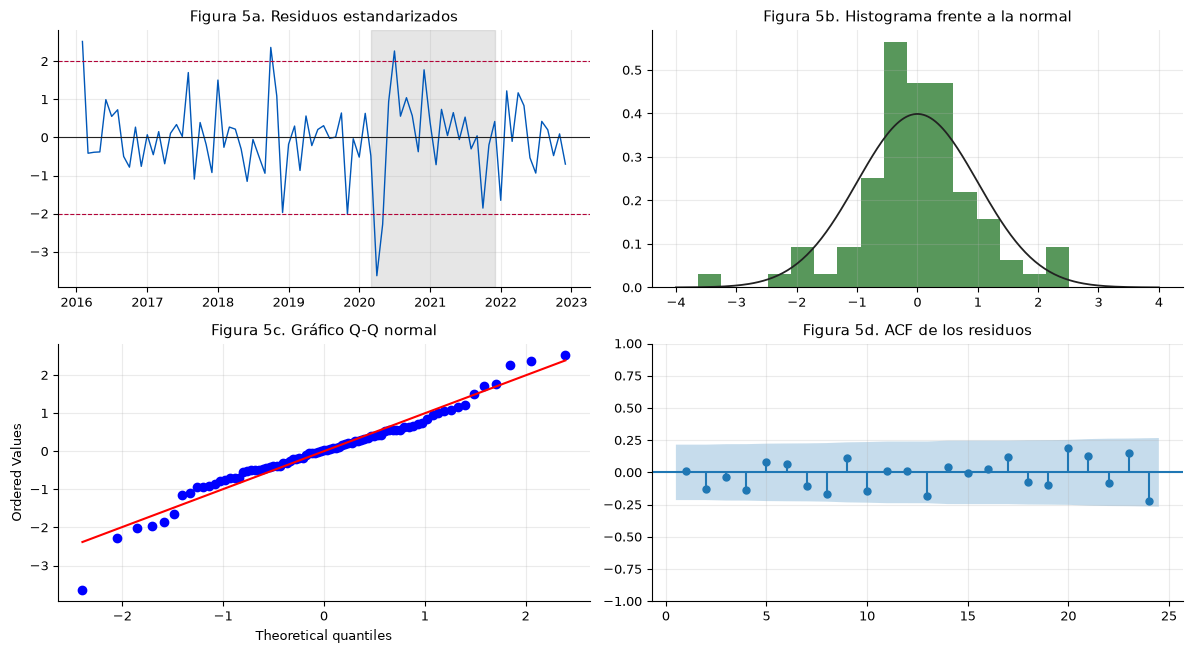

In [8]:
# ============================================================
# 4. Diagnóstico del modelo seleccionado: Ljung-Box (12 y 24), normalidad y ARCH-LM
# ============================================================
res_sel = sel["res"]
BURN = d_sel + D_sel * S                                   # los primeros residuos están afectados por la diferenciación
e = res_sel.resid.iloc[BURN:]
z = (e - e.mean()) / e.std()
k_arma = sel["k_arma"]

lb = acorr_ljungbox(e, lags=[12, 24], model_df=k_arma, return_df=True)
jb_est, jb_p = stats.jarque_bera(e)
sw_est, sw_p = stats.shapiro(e)
arch_lm, arch_p, _, _ = het_arch(e, nlags=12)
mitad = len(e) // 2
v1, v2 = float(e.iloc[:mitad].var(ddof=1)), float(e.iloc[mitad:].var(ddof=1))
F = v2 / v1
p_F = 2 * min(stats.f.cdf(F, len(e) - mitad - 1, mitad - 1), 1 - stats.f.cdf(F, len(e) - mitad - 1, mitad - 1))

tab4 = pd.DataFrame([
    {"supuesto": "Sin autocorrelación", "prueba": "Ljung-Box, rezago 12", "estadístico": lb["lb_stat"].iloc[0], "valor-p": lb["lb_pvalue"].iloc[0]},
    {"supuesto": "Sin autocorrelación", "prueba": "Ljung-Box, rezago 24", "estadístico": lb["lb_stat"].iloc[1], "valor-p": lb["lb_pvalue"].iloc[1]},
    {"supuesto": "Normalidad", "prueba": "Jarque-Bera", "estadístico": jb_est, "valor-p": jb_p},
    {"supuesto": "Normalidad", "prueba": "Shapiro-Wilk", "estadístico": sw_est, "valor-p": sw_p},
    {"supuesto": "Homocedasticidad", "prueba": "ARCH-LM (12 rezagos)", "estadístico": arch_lm, "valor-p": arch_p},
    {"supuesto": "Homocedasticidad", "prueba": "F de varianzas (2.ª / 1.ª mitad)", "estadístico": F, "valor-p": p_F},
])
tab4["conclusión (5 %)"] = np.where(tab4["valor-p"] > 0.05, "Cumple", "No cumple")
tab4[["estadístico", "valor-p"]] = tab4[["estadístico", "valor-p"]].round(3)
print(f"Tabla 4. Pruebas sobre los residuos de {seleccion} (n = {len(e)}; Ljung-Box con {k_arma} parámetro{'s' if k_arma != 1 else ''} AR/MA descontado{'s' if k_arma != 1 else ''})")
display(tab4.set_index("supuesto"))

# ---- Figura 5: residuos, histograma, Q-Q y ACF ----
fig, axes = plt.subplots(2, 2, figsize=(12, 6.6))
axes[0, 0].plot(z, color=AZUL, lw=1.0); axes[0, 0].axhline(0, color=NEGRO, lw=0.8)
for lim in (-2, 2):
    axes[0, 0].axhline(lim, color=ROJO, ls="--", lw=0.8)
axes[0, 0].axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=GRIS, alpha=0.25)
axes[0, 0].set_title("Figura 5a. Residuos estandarizados")
axes[0, 1].hist(z, bins=16, density=True, color=VERDE, alpha=0.8)
xs = np.linspace(-4, 4, 200); axes[0, 1].plot(xs, stats.norm.pdf(xs), color=NEGRO, lw=1.3)
axes[0, 1].set_title("Figura 5b. Histograma frente a la normal")
stats.probplot(z, dist="norm", plot=axes[1, 0]); axes[1, 0].set_title("Figura 5c. Gráfico Q-Q normal")
plot_acf(e, lags=24, ax=axes[1, 1], zero=False, title="Figura 5d. ACF de los residuos")
plt.tight_layout(); plt.show()

In [9]:
# Interpretación de la sección 4 (borrador)
ok_lb = bool((lb["lb_pvalue"] > 0.05).all()); ok_norm = (jb_p > 0.05) and (sw_p > 0.05); ok_het = (arch_p > 0.05) and (p_F > 0.05)
grandes = z[z.abs() > 2]
en_covid = [k for k in grandes.index if pd.Timestamp("2020-03-01") <= k <= pd.Timestamp("2021-12-01")]
mayores = grandes.abs().sort_values(ascending=False).index[:4]
txt_grandes = (f"Hay {len(grandes)} residuos que superan 2 desviaciones; los mayores están en {', '.join(f'{k:%Y-%m}' for k in mayores)}, y {len(en_covid)} de los {len(grandes)} caen en el periodo COVID-19. "
               if len(grandes) else "Ningún residuo supera 2 desviaciones. ")
if ok_lb and ok_het:
    cierre = "el modelo es válido para pronosticar" + ("; los intervalos también son confiables." if ok_norm else ", pero los intervalos de 95 % deben leerse como aproximados porque no hay normalidad.")
elif ok_lb:
    cierre = "el modelo captura la dependencia, pero la varianza no es constante, así que la incertidumbre puede estar mal calibrada"
else:
    cierre = "el modelo todavía deja estructura sin explicar y habría que mejorarlo (más términos o mejor tratamiento del COVID-19)"
texto = (
    "**Borrador (reescribir con mis palabras).** "
    f"Revisé tres cosas en los residuos del modelo elegido (Tabla 4 y Figura 5). Autocorrelación: Ljung-Box da {pp(lb['lb_pvalue'].iloc[0])} en el rezago 12 y {pp(lb['lb_pvalue'].iloc[1])} en el 24; "
    + ("como ambos superan 0,05, no se rechaza que los residuos sean ruido blanco. " if ok_lb else "al menos uno es menor que 0,05, así que quedó autocorrelación sin explicar. ")
    + f"Normalidad: Jarque-Bera da {pp(jb_p)} y Shapiro-Wilk {pp(sw_p)}; "
    + ("no se rechaza la normalidad. " if ok_norm else "se rechaza la normalidad en al menos una prueba. ")
    + f"Homocedasticidad: ARCH-LM da {pp(arch_p)} y el test F entre mitades {pp(p_F)}; "
    + ("no hay evidencia de varianza cambiante. " if ok_het else "hay evidencia de varianza cambiante. ")
    + txt_grandes
    + f"En conjunto, {cierre.rstrip('.')}."
)
interpretacion("4", texto)

**Borrador (reescribir con mis palabras).** Revisé tres cosas en los residuos del modelo elegido (Tabla 4 y Figura 5). Autocorrelación: Ljung-Box da p = 0,355 en el rezago 12 y p = 0,061 en el 24; como ambos superan 0,05, no se rechaza que los residuos sean ruido blanco. Normalidad: Jarque-Bera da p = 0,001 y Shapiro-Wilk p = 0,019; se rechaza la normalidad en al menos una prueba. Homocedasticidad: ARCH-LM da p = 0,639 y el test F entre mitades p = 0,246; no hay evidencia de varianza cambiante. Hay 6 residuos que superan 2 desviaciones; los mayores están en 2020-04, 2016-02, 2018-10, 2020-05, y 3 de los 6 caen en el periodo COVID-19. En conjunto, el modelo es válido para pronosticar, pero los intervalos de 95 % deben leerse como aproximados porque no hay normalidad.

*(137 palabras; límite 250)*

### Apoyo para el autor (borrar antes de entregar)

La celda siguiente imprime las cifras reales para completar la **Hoja de decisiones** y revisa los límites de extensión de la evaluación (hasta 3 figuras, una tabla y 250 palabras por sección técnica). Es solo una ayuda de trabajo: no forma parte del informe.

In [10]:
# ============================================================
# Apoyo: cifras para la Hoja de decisiones y control de límites
# ============================================================
fs, f0 = pruebas[(d_sel, D_sel)], pruebas[(0, 0)]
print("FILA 1 · Decisión: logaritmo, d = %d, D = %d" % (d_sel, D_sel))
print(f"  Evidencia: nivel ADF {pp(f0['ADF p'])}, KPSS {pp(f0['KPSS p'])}; después ADF {pp(fs['ADF p'])}, KPSS {pp(fs['KPSS p'])} (Fig. 2); λ Box-Cox = {c(lam)}")
print(f"FILA 2 · Candidatos: {', '.join(n.split('.')[0] + ' ' + tab2.loc[n, 'orden'] for n in tab2.index)}; sugerido por ACF/PACF: p={p_sug}, q={q_sug}, P={P_sug}, Q={Q_sug}")
print(f"FILA 3 · Elegido: {seleccion}; RMSE {c(tab3.loc[seleccion, 'RMSE'])} vs naive {c(tab3.loc['Naive estacional (referencia)', 'RMSE'])} GWh; MAE {c(tab3.loc[seleccion, 'MAE'])} vs {c(tab3.loc['Naive estacional (referencia)', 'MAE'])} GWh")
print(f"FILA 4 · Ljung-Box p(12) = {pv(lb['lb_pvalue'].iloc[0])}, p(24) = {pv(lb['lb_pvalue'].iloc[1])}; JB {pp(jb_p)}; ARCH-LM {pp(arch_p)}")
print()
resumen_lim = pd.DataFrame({"palabras de interpretación": PALABRAS, "límite": 250})
resumen_lim["cumple"] = resumen_lim["palabras de interpretación"] <= 250
resumen_lim["figuras en la sección"] = {"1": 2, "2": 1, "3": 1, "4": 1}
resumen_lim["tablas en la sección"] = {"1": 1, "2": 1, "3": 1, "4": 1}
display(resumen_lim)

FILA 1 · Decisión: logaritmo, d = 1, D = 1
  Evidencia: nivel ADF p = 0,391, KPSS p = 0,100; después ADF p < 0,001, KPSS p = 0,100 (Fig. 2); λ Box-Cox = 0,00
FILA 2 · Candidatos: A (0,1,0)(0,1,1)[12], B (0,1,1)(0,1,1)[12], C (1,1,1)(0,1,0)[12], D (1,1,1); sugerido por ACF/PACF: p=0, q=0, P=0, Q=1
FILA 3 · Elegido: B. SARIMA tipo «airline»; RMSE 7,13 vs naive 7,26 GWh; MAE 6,68 vs 6,53 GWh
FILA 4 · Ljung-Box p(12) = 0,355, p(24) = 0,061; JB p = 0,001; ARCH-LM p = 0,639



,palabras de interpretación,límite,cumple,figuras en la sección,tablas en la sección
1,189,250,True,2,1
2,176,250,True,1,1
3,199,250,True,1,1
4,137,250,True,1,1


## Conclusiones

In [11]:
sup_txt = "supera" if supera else "no supera"
ret = (f"El modelo elegido {sup_txt} al naive estacional en RMSE ({c(tab3.loc[seleccion, 'RMSE'])} frente a {c(tab3.loc['Naive estacional (referencia)', 'RMSE'])} GWh).")
valido = ("es válido para pronosticar" if (ok_lb and ok_het) else "es válido con reservas" if ok_lb else "es válido solo en forma parcial")
display(Markdown(
    "**Borrador (reescribir con mis palabras).**\n\n"
    f"1. La serie en logaritmos y en nivel recibe el veredicto «{pruebas[(0, 0)]['veredicto'].lower()}» (ADF {pp(pruebas[(0, 0)]['ADF p'])}; KPSS {pp(pruebas[(0, 0)]['KPSS p'])}) y conserva una estacionalidad fuerte (ACF(12) = {c(pruebas[(0, 0)]['ACF(12)'])}). Con d = {d_sel} y D = {D_sel} el veredicto es «{pruebas[(d_sel, D_sel)]['veredicto'].lower()}».\n\n"
    f"2. Con la ACF y la PACF propuse cuatro modelos de las familias SARIMA, ARMA y ARIMA, todos con el indicador `covid`; el efecto estimado del COVID-19 se ve en la Tabla 2.\n\n"
    f"3. El modelo elegido fue {seleccion}. {ret}\n\n"
    f"4. En los residuos, Ljung-Box {'no detecta' if ok_lb else 'detecta'} autocorrelación, la normalidad {'se cumple' if ok_norm else 'no se cumple del todo'} y la homocedasticidad {'se cumple' if ok_het else 'no se cumple del todo'}. En conjunto, el modelo {valido}.\n\n"
    "5. Limitaciones: la validación tiene solo 12 meses, el COVID-19 se modela con un único indicador y no se usó la temperatura. Mejora posible: más indicadores para el COVID-19, un modelo con temperatura (SARIMAX) o validación con origen móvil."
))

**Borrador (reescribir con mis palabras).**

1. La serie en logaritmos y en nivel recibe el veredicto «discrepante / no concluyente» (ADF p = 0,391; KPSS p = 0,100) y conserva una estacionalidad fuerte (ACF(12) = 0,62). Con d = 1 y D = 1 el veredicto es «estacionaria».

2. Con la ACF y la PACF propuse cuatro modelos de las familias SARIMA, ARMA y ARIMA, todos con el indicador `covid`; el efecto estimado del COVID-19 se ve en la Tabla 2.

3. El modelo elegido fue B. SARIMA tipo «airline». El modelo elegido supera al naive estacional en RMSE (7,13 frente a 7,26 GWh).

4. En los residuos, Ljung-Box no detecta autocorrelación, la normalidad no se cumple del todo y la homocedasticidad se cumple. En conjunto, el modelo es válido para pronosticar.

5. Limitaciones: la validación tiene solo 12 meses, el COVID-19 se modela con un único indicador y no se usó la temperatura. Mejora posible: más indicadores para el COVID-19, un modelo con temperatura (SARIMAX) o validación con origen móvil.

## Referencias (APA)

Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control, 19*(6), 716–723. https://doi.org/10.1109/TAC.1974.1100705

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association, 74*(366), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Jarque, C. M., & Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2), 163–172. https://doi.org/10.2307/1403192

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root: How sure are we that economic time series have a unit root? *Journal of Econometrics, 54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., & Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136

Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92–96. https://doi.org/10.25080/Majora-92bf1922-011

Shapiro, S. S., & Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3–4), 591–611. https://doi.org/10.1093/biomet/52.3-4.591

Universidad Andrés Bello. (s. f.). *MCDI505 — Análisis de series de tiempo: Caso transversal del curso* [Material de curso]. UNAB Online.

## Declaración de uso de asistentes de IA

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó asistentes de IA en esta entrega? | Sí. Se usó Claude (Anthropic) para preparar un borrador de esta entrega. **[COMPLETAR: confirmar herramienta y fecha]** |
| ¿En qué partes específicas? | Borrador del código de las cuatro secciones técnicas y borrador, en lenguaje sencillo, de los textos de interpretación, de las conclusiones y de la Hoja de decisiones. **[COMPLETAR: indicar qué textos reescribí yo con mis propias palabras y cuáles dejé como estaban]** |
| ¿Qué verificó de forma independiente y cómo? | **[COMPLETAR: por ejemplo, ejecuté el notebook desde un kernel reiniciado, revisé que cada cifra del texto coincida con la tabla o figura, comprobé las pruebas con las lecturas del curso. Escribir solo lo que realmente hice.]** |